# 03b · Ridge / Lasso — Bike Sharing Demand

**Responsable:** Pardo · **Plan:** `project_plan_crisp_dm.md` §6.2 · `plan_sprints.md` §5 (Sprint 2)

**Pregunta:** ¿qué codificación de la hora le sirve a un modelo lineal (entero, sin/cos, One-Hot, splines periódicos) y qué tan lejos queda Ridge del baseline de calendario (0.5585) y de LightGBM (0.4549)?

**Protocolo (igual que el notebook 03):** solo **train** (2011-01-01 a 2012-06-30), `get_cv()` (5 folds, ventana expansiva) y `validar_temporal`. Target `log1p(cnt)`, métrica de decisión **RMSLE**. El test no se usa. Todo ajuste (escalado, encoders, medianas) ocurre dentro del pipeline con el train de cada fold.

**Regla de adopción** (`CONFIG["regla_adopcion"]`): mejora media ≥ 0.002 **y** peor en ≤ 1 de 5 folds.

## 1) Preparación del entorno

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Lasso, Ridge
from sklearn.pipeline import Pipeline

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.features import agregar_lags
from src.evaluate import get_cv, validar_temporal
from src.lineales import PrepLineal

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "pardo" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Referencias medidas por Joan (docs/sprints/resumen_sprint_2_joan.md)
REF = {"Baseline calendario": 0.5585, "LightGBM + tuning": 0.4549, "LightGBM + lags (gap=24)": 0.3905}

### Punto de control 1

In [2]:
assert RANDOM_STATE == 42 and CONFIG["cv"]["n_splits"] == 5
print(" Configuración lista.")

 Configuración lista.


## 2) Datos de train y utilidades

`PrepLineal` (en `src/lineales.py`, archivo de Pardo) envuelve `build_preprocessor(escalar=True, ...)` sin modificarlo y añade **fuera de la función** la codificación extra de la hora, como pide el traspaso:

| `codif_hora` | Qué entra al modelo |
| :--- | :--- |
| `entero` | `hr` como número (escalado) |
| `sin_cos` | `hr_sin`, `hr_cos` |
| `onehot` | `hr_sin`, `hr_cos` + 24 columnas One-Hot de la hora |
| `splines` | `hr_sin`, `hr_cos` + B-splines cúbicos **periódicos** (13 nudos → 12 columnas) |

Ojo: el contrato ya incluye la categoría combinada `hr_workingday` en One-Hot (48 columnas), que por sí sola codifica la hora **y** su interacción con `workingday`. Por eso se mide con y sin ella.

In [3]:
df = load_data()
X_tr, y_tr = separar_xy(temporal_split(df)[0])
print(f"Train: {X_tr.shape}  ({X_tr.index.min()} → {X_tr.index.max()})")

RESULTADOS = {}

def evaluar(nombre, prep, reg=None, X=None, y=None, cv=None):
    """validar_temporal con Ridge(alpha=1) por defecto; guarda RMSLE por fold."""
    X = X_tr if X is None else X
    y = y_tr if y is None else y
    pipe = Pipeline([("prep", prep), ("reg", Ridge(alpha=1.0) if reg is None else reg)])
    por_fold, res = validar_temporal(pipe, X, y, nombre, cv=cv)
    n_cols = pipe.fit(X, np.log1p(y)).named_steps["prep"].transform(X.iloc[:5]).shape[1]
    RESULTADOS[nombre] = {"rmsle_folds": por_fold["rmsle"].to_numpy(), "media": res["rmsle_media"],
                          "std": res["rmsle_std"], "n_cols": n_cols}
    print(f"{nombre:45s} RMSLE {res['rmsle_media']:.4f} ± {res['rmsle_std']:.4f} | "
          + " ".join(f"{v:.4f}" for v in por_fold["rmsle"]) + f" | {n_cols} cols")
    return por_fold, res

def comparar(ref, var):
    """Aplica la regla de adopción de CONFIG a dos resultados ya calculados."""
    r, v = RESULTADOS[ref], RESULTADOS[var]
    mejora = r["media"] - v["media"]
    peor = int((v["rmsle_folds"] > r["rmsle_folds"] + 1e-6).sum())
    regla = CONFIG["regla_adopcion"]
    adopta = mejora >= regla["min_mejora_rmsle"] and peor <= regla["max_folds_peor"]
    print(f"{var!r} vs {ref!r}: mejora {mejora:+.4f}, peor en {peor}/5 folds -> {'ADOPTAR' if adopta else 'no adoptar'}")
    return adopta

def tabla(nombres):
    filas = [{"variante": n, **{f"f{i+1}": v for i, v in enumerate(RESULTADOS[n]["rmsle_folds"])},
              "media": RESULTADOS[n]["media"], "std": RESULTADOS[n]["std"], "cols": RESULTADOS[n]["n_cols"]}
             for n in nombres]
    return pd.DataFrame(filas).set_index("variante").round(4)

Train: (13003, 13)  (2011-01-01 00:00:00 → 2012-06-30 23:00:00)


## 3) Codificación de la hora **por sí sola** (sin `hr_workingday`)

Primero se quita `hr_workingday` para ver qué aporta cada codificación de la hora en un modelo lineal.

In [4]:
SOLAS = []
for c in ["entero", "sin_cos", "onehot", "splines"]:
    nombre = f"{c} (sin hr_workingday)"
    evaluar(nombre, PrepLineal(c, con_hr_workingday=False))
    SOLAS.append(nombre)
tabla(SOLAS)

entero (sin hr_workingday)                    RMSLE 1.0992 ± 0.1093 | 1.0576 1.0389 1.2747 1.1290 0.9957 | 17 cols


sin_cos (sin hr_workingday)                   RMSLE 0.9475 ± 0.0998 | 0.8875 0.9337 1.1168 0.9376 0.8620 | 18 cols


onehot (sin hr_workingday)                    RMSLE 0.6786 ± 0.1470 | 0.5987 0.6964 0.9236 0.6258 0.5485 | 42 cols


splines (sin hr_workingday)                   RMSLE 0.6800 ± 0.1470 | 0.6002 0.6968 0.9252 0.6280 0.5499 | 30 cols


,f1,f2,f3,f4,f5,media,std,cols
variante,,,,,,,,
entero (sin hr_workingday),1.0576,1.0389,1.2747,1.1290,0.9957,1.0992,0.1093,17
sin_cos (sin hr_workingday),0.8875,0.9337,1.1168,0.9376,0.8620,0.9475,0.0998,18
onehot (sin hr_workingday),0.5987,0.6964,0.9236,0.6258,0.5485,0.6786,0.1470,42
splines (sin hr_workingday),0.6002,0.6968,0.9252,0.6280,0.5499,0.6800,0.1470,30


**Lectura:** el entero es pésimo (un lineal solo puede subir o bajar con la hora), sin/cos mejora algo pero una sola onda no reproduce **dos picos** (mañana y tarde). One-Hot y splines sí los capturan y quedan prácticamente empatados; los splines con 12 columnas en lugar de 24.

## 4) Interacción hora × `workingday`

In [5]:
INTER = []
for c in ["onehot", "splines"]:
    nombre = f"{c} × workingday (sin hr_workingday)"
    evaluar(nombre, PrepLineal(c, con_hr_workingday=False, interaccion_workingday=True))
    INTER.append(nombre)
for k in [7, 9, 25]:
    nombre = f"splines k={k} × workingday (sin hr_workingday)"
    evaluar(nombre, PrepLineal("splines", con_hr_workingday=False, interaccion_workingday=True, n_knots=k))
    INTER.append(nombre)
tabla(INTER)

onehot × workingday (sin hr_workingday)       RMSLE 0.4931 ± 0.1614 | 0.3847 0.5322 0.7578 0.4253 0.3657 | 66 cols


splines × workingday (sin hr_workingday)      RMSLE 0.4966 ± 0.1605 | 0.3892 0.5337 0.7602 0.4307 0.3691 | 42 cols


splines k=7 × workingday (sin hr_workingday)  RMSLE 0.5791 ± 0.1406 | 0.4821 0.5943 0.8154 0.5312 0.4726 | 30 cols


splines k=9 × workingday (sin hr_workingday)  RMSLE 0.5404 ± 0.1513 | 0.4316 0.5671 0.7908 0.4892 0.4231 | 34 cols


splines k=25 × workingday (sin hr_workingday) RMSLE 0.4932 ± 0.1614 | 0.3849 0.5322 0.7579 0.4254 0.3656 | 66 cols


,f1,f2,f3,f4,f5,media,std,cols
variante,,,,,,,,
onehot × workingday (sin hr_workingday),0.3847,0.5322,0.7578,0.4253,0.3657,0.4931,0.1614,66
splines × workingday (sin hr_workingday),0.3892,0.5337,0.7602,0.4307,0.3691,0.4966,0.1605,42
splines k=7 × workingday (sin hr_workingday),0.4821,0.5943,0.8154,0.5312,0.4726,0.5791,0.1406,30
splines k=9 × workingday (sin hr_workingday),0.4316,0.5671,0.7908,0.4892,0.4231,0.5404,0.1513,34
splines k=25 × workingday (sin hr_workingday),0.3849,0.5322,0.7579,0.4254,0.3656,0.4932,0.1614,66


**Lectura:** el salto grande (≈ 0.68 → ≈ 0.49) viene de dejar que el perfil horario sea **distinto en laborables y no laborables** (picos de conmutación vs. curva de ocio). One-Hot × `workingday` equivale exactamente a `hr_workingday` del contrato. Con splines, el número de nudos regula la suavidad: 7 nudos suaviza demasiado los picos; con 13 a 25 se recupera el One-Hot.

## 5) Las cuatro codificaciones **con** el contrato (`hr_workingday` incluido)

In [6]:
CONTRATO = []
for c in ["entero", "sin_cos", "onehot", "splines"]:
    nombre = f"{c} + hr_workingday"
    evaluar(nombre, PrepLineal(c))
    CONTRATO.append(nombre)
tabla(CONTRATO)

entero + hr_workingday                        RMSLE 0.4930 ± 0.1614 | 0.3831 0.5318 0.7578 0.4264 0.3661 | 65 cols


sin_cos + hr_workingday                       RMSLE 0.4932 ± 0.1612 | 0.3845 0.5322 0.7575 0.4257 0.3661 | 66 cols


onehot + hr_workingday                        RMSLE 0.4930 ± 0.1612 | 0.3843 0.5322 0.7574 0.4254 0.3659 | 90 cols


splines + hr_workingday                       RMSLE 0.4930 ± 0.1612 | 0.3843 0.5322 0.7574 0.4254 0.3659 | 78 cols


,f1,f2,f3,f4,f5,media,std,cols
variante,,,,,,,,
entero + hr_workingday,0.3831,0.5318,0.7578,0.4264,0.3661,0.4930,0.1614,65
sin_cos + hr_workingday,0.3845,0.5322,0.7575,0.4257,0.3661,0.4932,0.1612,66
onehot + hr_workingday,0.3843,0.5322,0.7574,0.4254,0.3659,0.4930,0.1612,90
splines + hr_workingday,0.3843,0.5322,0.7574,0.4254,0.3659,0.4930,0.1612,78


In [7]:
for c in ["sin_cos", "onehot", "splines"]:
    comparar("entero + hr_workingday", f"{c} + hr_workingday")

'sin_cos + hr_workingday' vs 'entero + hr_workingday': mejora -0.0002, peor en 2/5 folds -> no adoptar
'onehot + hr_workingday' vs 'entero + hr_workingday': mejora -0.0000, peor en 2/5 folds -> no adoptar
'splines + hr_workingday' vs 'entero + hr_workingday': mejora -0.0000, peor en 2/5 folds -> no adoptar


**Lectura:** con `hr_workingday` en el modelo, **la codificación de la hora deja de importar** (diferencias ≤ 0.0002). La respuesta a "splines vs One-Hot vs sin/cos" es: importan **solo si no está la interacción**; con ella, el contrato ya tiene la mejor codificación posible para la forma del perfil horario. Se mantiene `hora='entero'` (`CONFIG["features"]`).

## 6) Lo que sí le falta al lineal: interacción hora × temperatura

El efecto de la temperatura no es igual a las 3 a. m. que a las 5 p. m. Un lineal no lo aprende solo; se le da como la base de splines multiplicada por `temp_c` (escalada).

In [8]:
evaluar("splines × temp + hr_workingday", PrepLineal("splines", interaccion_temp=True))
evaluar("onehot × temp + hr_workingday", PrepLineal("onehot", interaccion_temp=True))
tabla(["entero + hr_workingday", "splines × temp + hr_workingday", "onehot × temp + hr_workingday"])

splines × temp + hr_workingday                RMSLE 0.4885 ± 0.1583 | 0.3821 0.5243 0.7489 0.4235 0.3638 | 90 cols


onehot × temp + hr_workingday                 RMSLE 0.4885 ± 0.1583 | 0.3821 0.5245 0.7488 0.4233 0.3637 | 114 cols


,f1,f2,f3,f4,f5,media,std,cols
variante,,,,,,,,
entero + hr_workingday,0.3831,0.5318,0.7578,0.4264,0.3661,0.4930,0.1614,65
splines × temp + hr_workingday,0.3821,0.5243,0.7489,0.4235,0.3638,0.4885,0.1583,90
onehot × temp + hr_workingday,0.3821,0.5245,0.7488,0.4233,0.3637,0.4885,0.1583,114


In [9]:
ADOPTA_TEMP = comparar("entero + hr_workingday", "splines × temp + hr_workingday")

'splines × temp + hr_workingday' vs 'entero + hr_workingday': mejora +0.0045, peor en 0/5 folds -> ADOPTAR


Se adopta la versión con **splines** (mismo RMSLE que One-Hot con 24 columnas menos). Es la primera variante que mejora en **los 5 folds**.

## 7) Regularización: `alpha` de Ridge y Lasso

In [10]:
MEJOR = dict(codif_hora="splines", interaccion_temp=True)
ALPHAS = []
for a in [0.1, 0.3, 3, 10, 100]:
    nombre = f"Ridge alpha={a}"
    evaluar(nombre, PrepLineal(**MEJOR), Ridge(alpha=a))
    ALPHAS.append(nombre)
for a in [1e-4, 3e-4, 1e-3, 1e-2]:
    nombre = f"Lasso alpha={a}"
    evaluar(nombre, PrepLineal(**MEJOR), Lasso(alpha=a, max_iter=50_000))
    ALPHAS.append(nombre)
tabla(["splines × temp + hr_workingday", *ALPHAS])

Ridge alpha=0.1                               RMSLE 0.4885 ± 0.1582 | 0.3819 0.5245 0.7486 0.4234 0.3640 | 90 cols


Ridge alpha=0.3                               RMSLE 0.4885 ± 0.1582 | 0.3820 0.5244 0.7487 0.4234 0.3639 | 90 cols


Ridge alpha=3                                 RMSLE 0.4886 ± 0.1584 | 0.3826 0.5240 0.7494 0.4238 0.3634 | 90 cols


Ridge alpha=10                                RMSLE 0.4897 ± 0.1589 | 0.3856 0.5237 0.7516 0.4252 0.3624 | 90 cols


Ridge alpha=100                               RMSLE 0.5298 ± 0.1557 | 0.4602 0.5547 0.7860 0.4660 0.3823 | 90 cols


Lasso alpha=0.0001                            RMSLE 0.4884 ± 0.1585 | 0.3814 0.5253 0.7488 0.4233 0.3633 | 90 cols


Lasso alpha=0.0003                            RMSLE 0.4888 ± 0.1590 | 0.3822 0.5270 0.7494 0.4234 0.3621 | 90 cols


Lasso alpha=0.001                             RMSLE 0.4917 ± 0.1600 | 0.3869 0.5345 0.7521 0.4252 0.3596 | 90 cols


Lasso alpha=0.01                              RMSLE 0.5965 ± 0.1487 | 0.5165 0.6351 0.8352 0.5437 0.4522 | 90 cols


,f1,f2,f3,f4,f5,media,std,cols
variante,,,,,,,,
splines × temp + hr_workingday,0.3821,0.5243,0.7489,0.4235,0.3638,0.4885,0.1583,90
Ridge alpha=0.1,0.3819,0.5245,0.7486,0.4234,0.3640,0.4885,0.1582,90
Ridge alpha=0.3,0.3820,0.5244,0.7487,0.4234,0.3639,0.4885,0.1582,90
Ridge alpha=3,0.3826,0.5240,0.7494,0.4238,0.3634,0.4886,0.1584,90
Ridge alpha=10,0.3856,0.5237,0.7516,0.4252,0.3624,0.4897,0.1589,90
Ridge alpha=100,0.4602,0.5547,0.7860,0.4660,0.3823,0.5298,0.1557,90
Lasso alpha=0.0001,0.3814,0.5253,0.7488,0.4233,0.3633,0.4884,0.1585,90
Lasso alpha=0.0003,0.3822,0.5270,0.7494,0.4234,0.3621,0.4888,0.1590,90
Lasso alpha=0.001,0.3869,0.5345,0.7521,0.4252,0.3596,0.4917,0.1600,90


In [11]:
for n in ["Ridge alpha=0.3", "Ridge alpha=3", "Lasso alpha=0.0001"]:
    comparar("splines × temp + hr_workingday", n)

'Ridge alpha=0.3' vs 'splines × temp + hr_workingday': mejora +0.0000, peor en 2/5 folds -> no adoptar
'Ridge alpha=3' vs 'splines × temp + hr_workingday': mejora -0.0001, peor en 3/5 folds -> no adoptar
'Lasso alpha=0.0001' vs 'splines × temp + hr_workingday': mejora +0.0001, peor en 1/5 folds -> no adoptar


**Lectura:** la superficie es plana entre `alpha` 0.1 y 3; ningún cambio cumple la regla, se mantiene **Ridge `alpha=1`**. Lasso no mejora: con ~13 000 filas y ~90 columnas no hay sobreajuste que la selección de variables corrija; con `alpha` alto elimina columnas útiles y empeora. Ver cuántos coeficientes anula:

In [12]:
pipe_lasso = Pipeline([("prep", PrepLineal(**MEJOR)), ("reg", Lasso(alpha=1e-3, max_iter=50_000))]).fit(X_tr, np.log1p(y_tr))
coef = pd.Series(pipe_lasso.named_steps["reg"].coef_, index=pipe_lasso.named_steps["prep"].transform(X_tr.iloc[:5]).columns)
print(f"Lasso alpha=1e-3: {int((coef == 0).sum())} de {len(coef)} coeficientes en cero")
print("Anulados:", ", ".join(coef[coef == 0].index[:20]), "...")

Lasso alpha=1e-3: 28 de 90 coeficientes en cero
Anulados: weathersit_2, hr_workingday_14_0, hr_workingday_15_0, hr_workingday_16_0, hr_workingday_17_0, hr_workingday_18_0, hr_workingday_19_0, hr_workingday_1_0, hr_workingday_20_0, hr_workingday_21_0, hr_workingday_22_0, hr_workingday_23_1, hr_workingday_4_0, hr_workingday_9_0, hr_splines_0, hr_splines_1, hr_splines_2, hr_splines_4, hr_splines_5, hr_splines_6 ...


## 8) Lags (`lag_24`, `lag_168`) con validación `gap=24`

Pendiente de decisión del grupo (punto 8a). Se mide igual que en la ficha 7 de Joan: `agregar_lags` sobre la serie completa, `get_cv(gap=24)` y la referencia recalculada con ese mismo gap. Los NaN de los lags se imputan con la mediana de train del fold (dentro de `PrepLineal`).

In [13]:
X_l, y_l = separar_xy(temporal_split(agregar_lags(df))[0])
cv24 = get_cv(gap=CONFIG["lgbm"]["gap_con_lags"])
evaluar("Ridge final, gap=24 (sin lags)", PrepLineal(**MEJOR), cv=cv24)
evaluar("Ridge final + lag_24 + lag_168, gap=24", PrepLineal(**MEJOR, lags=("lag_24", "lag_168")), X=X_l, y=y_l, cv=cv24)
tabla(["Ridge final, gap=24 (sin lags)", "Ridge final + lag_24 + lag_168, gap=24"])

Ridge final, gap=24 (sin lags)                RMSLE 0.4889 ± 0.1579 | 0.3818 0.5243 0.7487 0.4246 0.3650 | 90 cols


Ridge final + lag_24 + lag_168, gap=24        RMSLE 0.4766 ± 0.1335 | 0.3810 0.5031 0.6958 0.4338 0.3693 | 92 cols


,f1,f2,f3,f4,f5,media,std,cols
variante,,,,,,,,
"Ridge final, gap=24 (sin lags)",0.3818,0.5243,0.7487,0.4246,0.3650,0.4889,0.1579,90
"Ridge final + lag_24 + lag_168, gap=24",0.3810,0.5031,0.6958,0.4338,0.3693,0.4766,0.1335,92


In [14]:
ADOPTA_LAGS = comparar("Ridge final, gap=24 (sin lags)", "Ridge final + lag_24 + lag_168, gap=24")

'Ridge final + lag_24 + lag_168, gap=24' vs 'Ridge final, gap=24 (sin lags)': mejora +0.0123, peor en 2/5 folds -> no adoptar


**Lectura:** los lags bajan la media (~0.012) pero la ganancia se concentra en los folds 2 y 3 y empeoran los folds 4 y 5. **No cumple la regla** para Ridge, a diferencia de LightGBM (ficha 7). Un lineal usa el lag como una escala fija, sin poder condicionarlo a la hora ni al clima. Este dato sirve para la decisión 8a: si se exige "lags para todos", Ridge mejora en promedio, pero no de forma consistente.

## 9) Resumen y figuras

In [15]:
FINALES = ["entero (sin hr_workingday)", "sin_cos (sin hr_workingday)", "onehot (sin hr_workingday)",
           "splines (sin hr_workingday)", "splines × workingday (sin hr_workingday)",
           "entero + hr_workingday", "splines × temp + hr_workingday", "Ridge final + lag_24 + lag_168, gap=24"]
resumen = tabla(FINALES)
resumen["vs baseline"] = ((REF["Baseline calendario"] - resumen["media"]) / REF["Baseline calendario"] * 100).round(1).astype(str) + " %"
resumen

,f1,f2,f3,f4,f5,media,std,cols,vs baseline
variante,,,,,,,,,
entero (sin hr_workingday),1.0576,1.0389,1.2747,1.1290,0.9957,1.0992,0.1093,17,-96.8 %
sin_cos (sin hr_workingday),0.8875,0.9337,1.1168,0.9376,0.8620,0.9475,0.0998,18,-69.7 %
onehot (sin hr_workingday),0.5987,0.6964,0.9236,0.6258,0.5485,0.6786,0.1470,42,-21.5 %
splines (sin hr_workingday),0.6002,0.6968,0.9252,0.6280,0.5499,0.6800,0.1470,30,-21.8 %
splines × workingday (sin hr_workingday),0.3892,0.5337,0.7602,0.4307,0.3691,0.4966,0.1605,42,11.1 %
entero + hr_workingday,0.3831,0.5318,0.7578,0.4264,0.3661,0.4930,0.1614,65,11.7 %
splines × temp + hr_workingday,0.3821,0.5243,0.7489,0.4235,0.3638,0.4885,0.1583,90,12.5 %
"Ridge final + lag_24 + lag_168, gap=24",0.3810,0.5031,0.6958,0.4338,0.3693,0.4766,0.1335,92,14.7 %


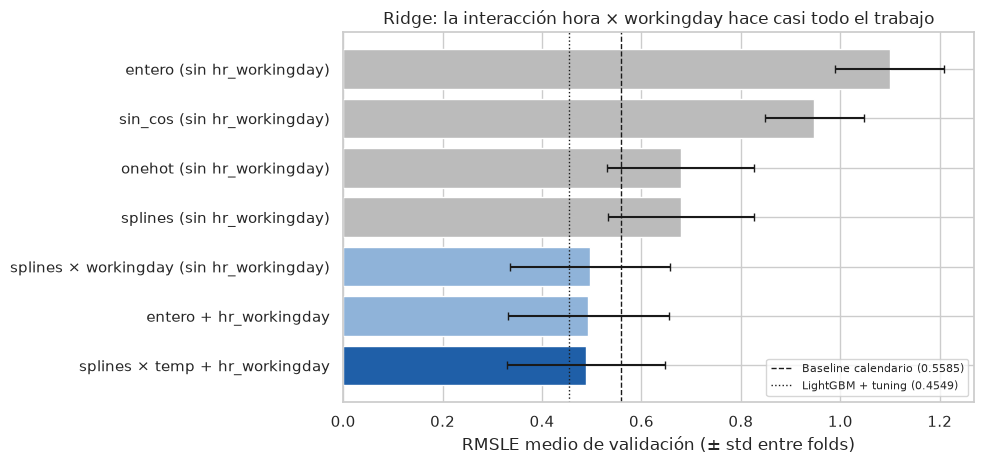

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.8))
orden = FINALES[:7]
medias = [RESULTADOS[n]["media"] for n in orden]
stds = [RESULTADOS[n]["std"] for n in orden]
colores = ["#bbb"] * 4 + ["#8fb3d9", "#8fb3d9", "#1f5fa8"]
ax.barh(orden[::-1], medias[::-1], xerr=stds[::-1], color=colores[::-1], capsize=3)
for etiqueta, v, ls in [("Baseline calendario", REF["Baseline calendario"], "--"), ("LightGBM + tuning", REF["LightGBM + tuning"], ":")]:
    ax.axvline(v, color="k", ls=ls, lw=1, label=f"{etiqueta} ({v})")
ax.legend(loc="lower right", fontsize=8)
ax.set_xlabel("RMSLE medio de validación (± std entre folds)")
ax.set_title("Ridge: la interacción hora × workingday hace casi todo el trabajo")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_ridge_codificaciones.png", dpi=120); plt.show()

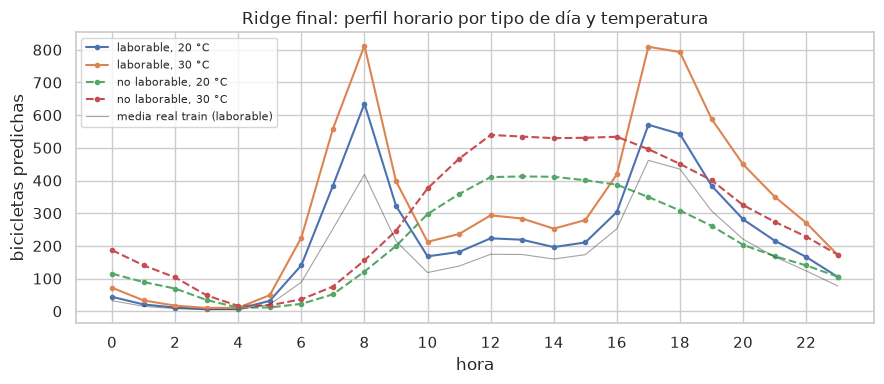

In [17]:
# Perfil horario que aprende el Ridge final: día tipo de junio 2012, clima medio, despejado
final = Pipeline([("prep", PrepLineal(**MEJOR)), ("reg", Ridge(alpha=1.0))]).fit(X_tr, np.log1p(y_tr))
tipo = X_tr.loc["2012-06-01":"2012-06-30"].median(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 4))
for wd, temp_c in [(1, 20), (1, 30), (0, 20), (0, 30)]:
    D = pd.DataFrame([tipo] * 24).reset_index(drop=True)
    D["hr"], D["workingday"], D["temp"], D["atemp"] = range(24), wd, temp_c / 41, temp_c / 41 * 41 / 50
    D["weathersit"], D["season"], D["yr"], D["dteday"] = 1, 2, 1, pd.Timestamp("2012-06-15")
    D.index = pd.date_range("2012-06-15", periods=24, freq="h")
    ax.plot(range(24), np.expm1(final.predict(D)), marker="o", ms=3,
            ls="-" if wd else "--", label=f"{'laborable' if wd else 'no laborable'}, {temp_c} °C")
real = pd.DataFrame({"hr": X_tr["hr"], "wd": X_tr["workingday"], "cnt": y_tr}).groupby(["wd", "hr"])["cnt"].mean().unstack(0)
ax.plot(real.index, real[1], color="k", lw=0.8, alpha=0.4, label="media real train (laborable)")
ax.set_xlabel("hora"); ax.set_ylabel("bicicletas predichas"); ax.set_xticks(range(0, 24, 2)); ax.legend(fontsize=8)
ax.set_title("Ridge final: perfil horario por tipo de día y temperatura")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_ridge_perfil_horario.png", dpi=120); plt.show()

### Punto de control final

In [18]:
r = RESULTADOS["splines × temp + hr_workingday"]
assert r["media"] < REF["Baseline calendario"], "Ridge debería superar el baseline de calendario"
assert ADOPTA_TEMP
print(f" Ridge final: RMSLE {r['media']:.4f} ± {r['std']:.4f} "
      f"({(REF['Baseline calendario'] - r['media']) / REF['Baseline calendario']:.1%} mejor que el baseline; "
      f"{r['media'] - REF['LightGBM + tuning']:+.4f} vs LightGBM con tuning).")

 Ridge final: RMSLE 0.4885 ± 0.1583 (12.5% mejor que el baseline; +0.0336 vs LightGBM con tuning).


## 10) Conclusiones (Sprint 2, Pardo)

1. **Codificación de la hora:** sola, el orden es One-Hot ≈ splines periódicos ≪ sin/cos ≪ entero. Con la interacción `hr_workingday` del contrato, **las cuatro empatan** (±0.0002): no se cambia `CONFIG["features"]["hora"]`.
2. **Lo que mueve el error es la interacción**, no la codificación: hora × `workingday` (contrato) y hora × temperatura (nuevo, adoptado: −0.0045, mejor en 5/5 folds).
3. **Modelo lineal final:** `PrepLineal(codif_hora="splines", interaccion_temp=True)` + `Ridge(alpha=1)`, **RMSLE 0.4885 ± 0.1583**, 12.5 % mejor que el baseline de calendario y 0.034 peor que LightGBM con tuning (misma validación `gap=0`).
4. **Lasso** no aporta; **lags** mejoran la media de Ridge pero no son consistentes entre folds (no se adoptan con la regla actual).
5. Como LightGBM, el fold 3 (train solo 2011, valida 2012) domina el error: el lineal tampoco extrapola bien el crecimiento interanual con una sola variable `yr`.

Fichas 8 a 10 en `reports/decisiones.md`; resumen en `docs/sprints/resumen_sprint_2_pardo.md`.